In [30]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as scp
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [31]:
from sklearn import datasets

data = datasets.fetch_california_housing()

print(data.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [32]:
df = pd.DataFrame(data.data, columns=data.feature_names)
df['MedHouseVal'] = data.target

df = df[:1000]

df.describe() 

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.00000,1000.000000
mean,3.842993,37.492000,5.226843,1.052389,1219.019000,2.715794,37.73947,-122.15555,2.095186
std,1.811349,13.184604,1.171739,0.107238,996.689703,0.729800,0.09757,0.11630,0.890378
min,0.499900,2.000000,1.714286,0.571429,18.000000,1.437141,37.47000,-122.34000,0.600000
25%,2.562500,28.000000,4.419560,1.000000,661.750000,2.297864,37.68000,-122.25000,1.486500
50%,3.514050,39.000000,5.083685,1.045584,966.500000,2.643192,37.76000,-122.18000,1.953500
75%,4.899225,51.000000,5.957536,1.089518,1447.750000,3.008650,37.81000,-122.08000,2.542000
max,13.499000,52.000000,9.210227,2.700730,12203.000000,12.234043,37.90000,-121.61000,5.000010


In [33]:
pip install skimpy

Note: you may need to restart the kernel to use updated packages.


In [34]:
from skimpy import skim

skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 1000   │ │ float64     │ 9     │                                                          │
│ │ Number of columns │ 9      │ └─────────────┴───────┘                                                          │
│ └───────────────────┴────────┘                                                                                  │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓  │
│ ┃ column        ┃ NA  ┃ NA %  ┃ mean    ┃ sd       ┃ p0      ┃ p25     ┃ p50     ┃ p75     ┃ p100   ┃ hist   ┃  │
│ ┡━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩  │
│ │ MedInc        │   0 │     0 │   3.843 │    1.811 │  0.4999 │   2.562 │   3.514 │   4.899 │   13.5 │  ▅█▃▁  │  │
│ │ HouseAge      │   0 │     0 │   37.49 │    13.18 │       2 │      28 │      39 │      51 │     52 │ ▁▂▂▃▄█ │  │
│ │ AveRooms      │   0 │     0 │   5.227 │    1.172 │   1.714 │    4.42 │   5.084 │   5.958 │   9.21 │  ▃█▅▂  │  │
│ │ AveBedrms     │   0 │     0 │   1.052 │   0.1072 │  0.5714 │       1 │   1.046 │    1.09 │  2.701 │    █   │  │
│ │ Population    │   0 │     0 │    1219 │    996.7 │      18 │   661.8 │   966.5 │    1448 │  12200 │   █▁   │  │
│ │ AveOccup      │   0 │     0 │   2.716 │   0.7298 │   1.437 │   2.298 │   2.643 │   3.009 │  12.23 │   █▁   │  │
│ │ Latitude      │   0 │     0 │   37.74 │  0.09757 │   37.47 │   37.68 │   37.76 │   37.81 │   37.9 │ ▁▂▄▅█▅ │  │
│ │ Longitude     │   0 │     0 │  -122.2 │   0.1163 │  -122.3 │  -122.2 │  -122.2 │  -122.1 │ -121.6 │  █▇▄▂  │  │
│ │ MedHouseVal   │   0 │     0 │   2.095 │   0.8904 │     0.6 │   1.487 │   1.954 │   2.542 │      5 │ ▄█▆▃▁▁ │  │
│ └───────────────┴─────┴───────┴─────────┴──────────┴─────────┴─────────┴─────────┴─────────┴────────┴────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

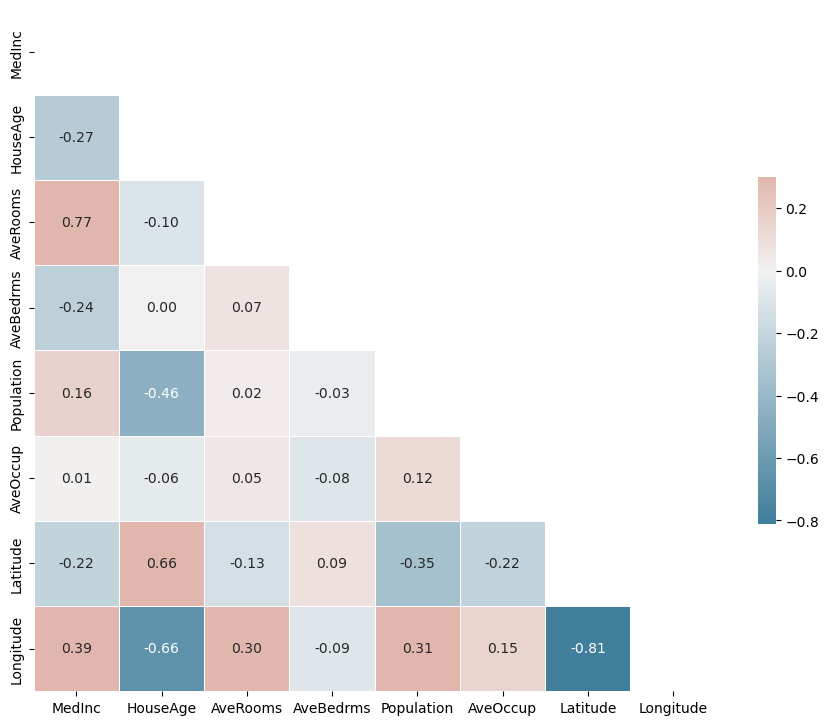

In [35]:
corr = df.drop('MedHouseVal', axis=1).corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.show()

Мультиколлинеарность между признаками:
AveRooms-MedInc	
Population-HouseAge	
Latitude-HouseAge	
Longitude-HouseAge	
Longitude-Latitude	

In [36]:
# "Грязная" модель
import statsmodels.formula.api as smf

lm = smf.ols("MedHouseVal~MedInc+HouseAge+AveRooms+AveBedrms", df).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            MedHouseVal   R-squared:                       0.594
Model:                            OLS   Adj. R-squared:                  0.593
Method:                 Least Squares   F-statistic:                     364.5
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          3.32e-193
Time:                        20:40:46   Log-Likelihood:                -851.18
No. Observations:                1000   AIC:                             1712.
Df Residuals:                     995   BIC:                             1737.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.2314      0.210      1.100      0.272      -0.181       0.644
MedInc         0.4192      0.019     22.414      0.000       0.382       0.456
HouseAge       0.0056      0.001      3.832      0.000       0.003       0.008
AveRooms      -0.0543      0.027     -1.996      0.046      -0.108      -0.001
AveBedrms      0.3115      0.192      1.622      0.105      -0.065       0.688
==============================================================================
Omnibus:                      312.710   Durbin-Watson:                   1.097
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1666.392
Skew:                           1.336   Prob(JB):                         0.00
Kurtosis:                       8.732   Cond. No.                         617.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Отберите наиболее значимые факторы и постройте наиболее лучшую модель, где результативным признаком является MedHouseVal.
Перед построением модели отберите факторы воспользовавшись функцией sns.pairplot из пакета seaborn
После постройте аналогичную модель с очищенными данными от выбросов методом Тьюки (по выбранным факторным признакам), наличие выбросов определите с помощью визуализации ящиковой диаграммы (boxplot).

In [37]:
pip install seaborn 

Note: you may need to restart the kernel to use updated packages.


In [38]:
import seaborn as sns 

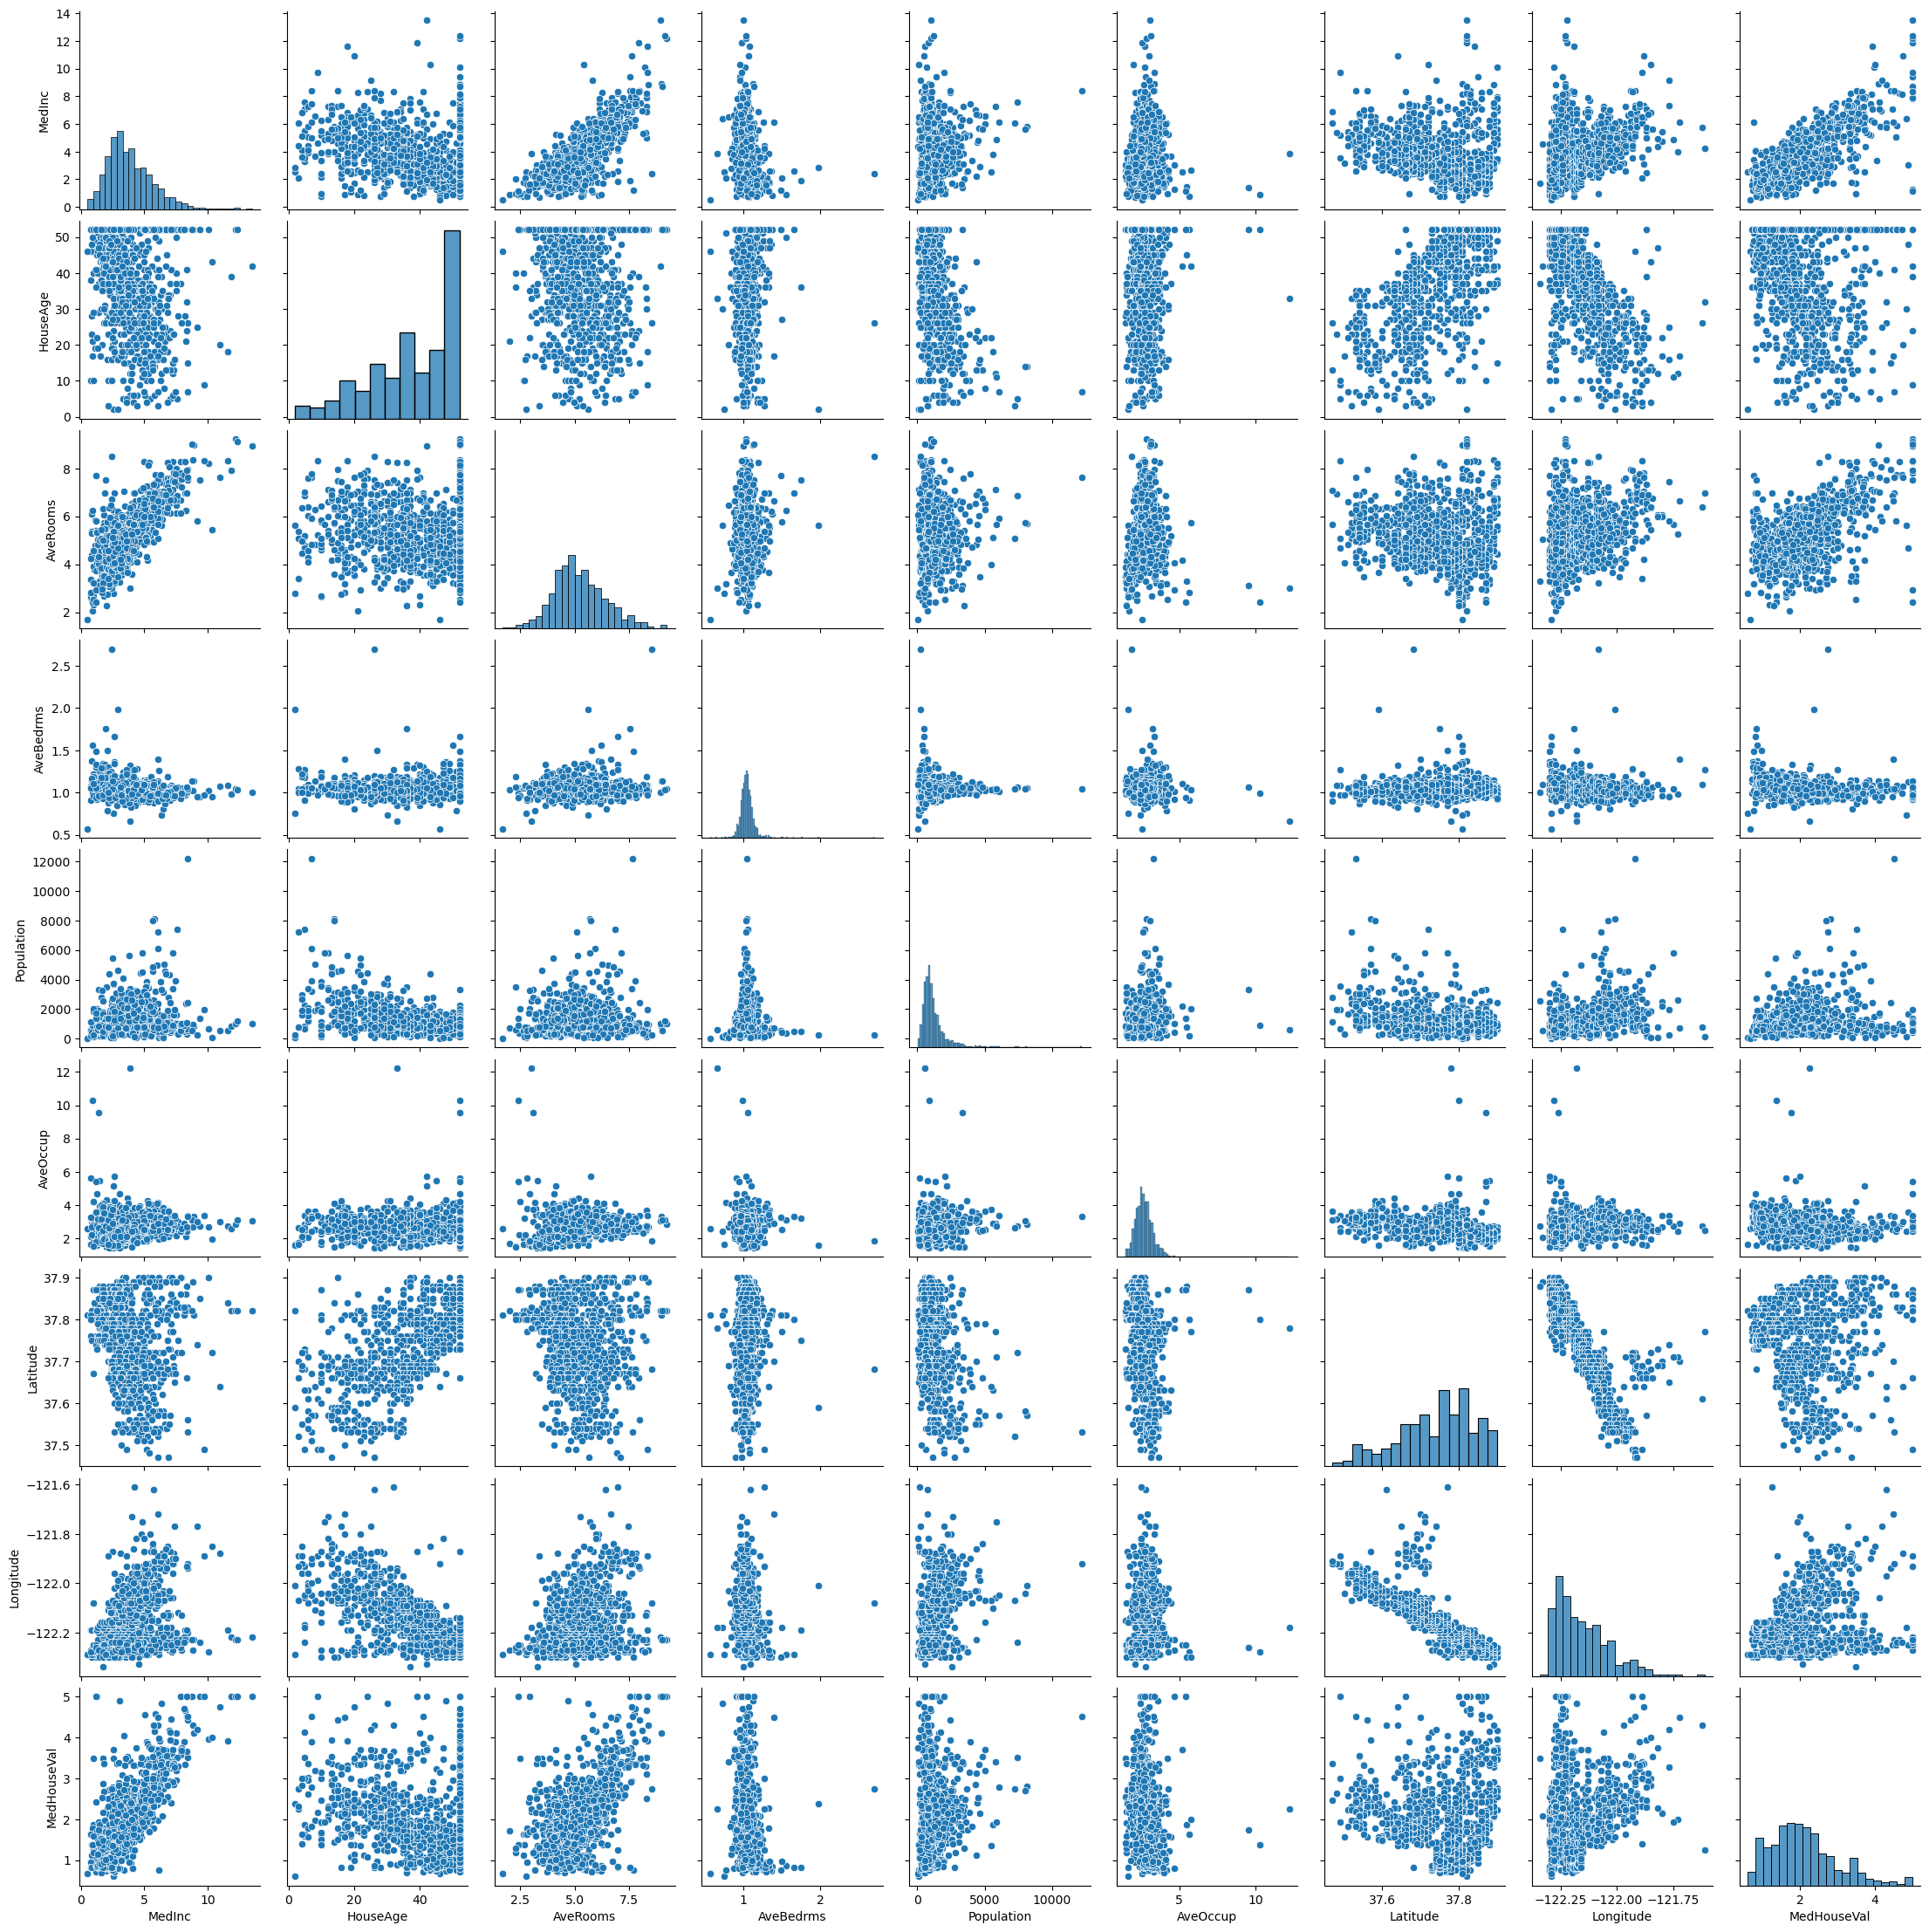

In [39]:
sns.pairplot(df)

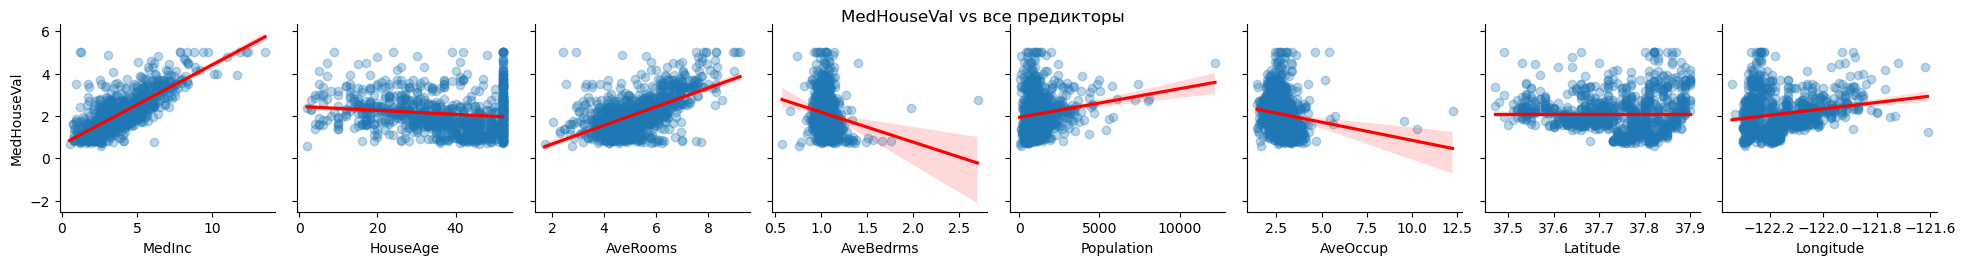

In [40]:
sns.pairplot(df, 
             y_vars=['MedHouseVal'], 
             x_vars=[col for col in df.columns if col != 'MedHouseVal'],
             kind='reg',
             plot_kws={'line_kws':{'color':'red'}, 'scatter_kws': {'alpha': 0.3}})
plt.suptitle('MedHouseVal vs все предикторы', y=1.02)
plt.show()

Корреляция со всеми признаками

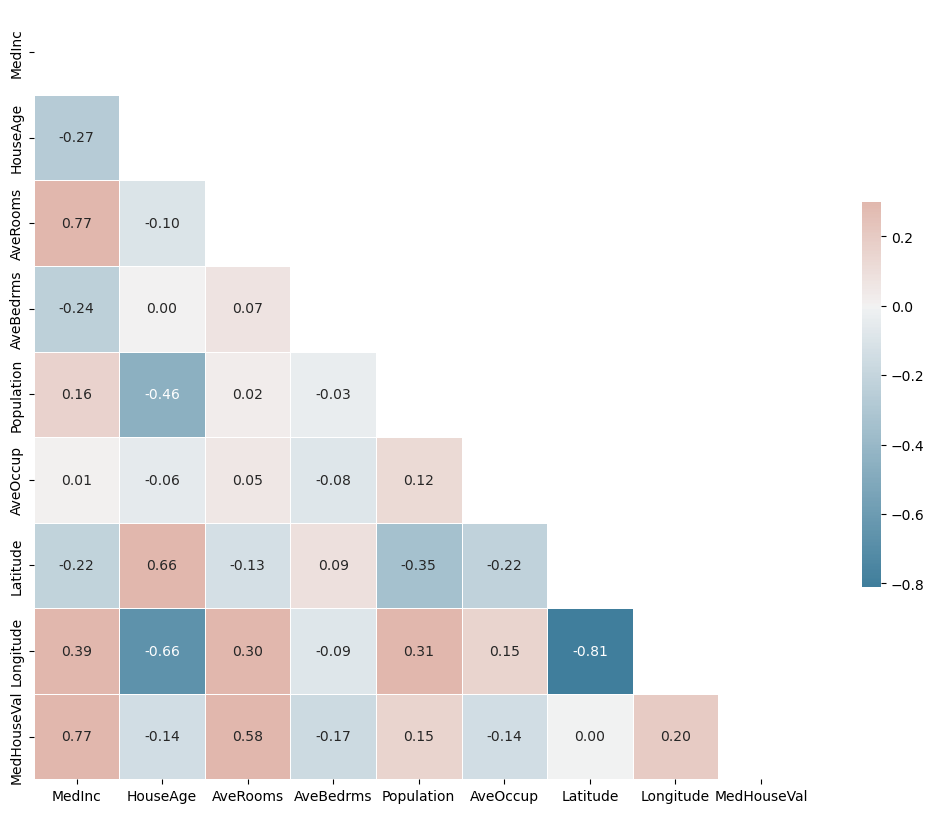

In [42]:
corr = df.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(15, 10))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.show()

In [43]:
import statsmodels.formula.api as smf

lm = smf.ols("MedHouseVal~Longitude+AveBedrms+MedInc", df).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            MedHouseVal   R-squared:                       0.600
Model:                            OLS   Adj. R-squared:                  0.598
Method:                 Least Squares   F-statistic:                     497.2
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          2.16e-197
Time:                        20:41:26   Log-Likelihood:                -844.69
No. Observations:                1000   AIC:                             1697.
Df Residuals:                     996   BIC:                             1717.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -109.6376     20.359     -5.385      0.000    -149.590     -69.686
Longitude     -0.9011      0.167     -5.411      0.000      -1.228      -0.574
AveBedrms      0.1091      0.171      0.637      0.525      -0.227       0.445
MedInc         0.4008      0.011     36.564      0.000       0.379       0.422
==============================================================================
Omnibus:                      335.336   Durbin-Watson:                   1.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1956.556
Skew:                           1.414   Prob(JB):                         0.00
Kurtosis:                       9.242   Cond. No.                     1.39e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.39e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [44]:
import statsmodels.formula.api as smf

lm = smf.ols("MedHouseVal~AveOccup+AveRooms+MedInc", df).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            MedHouseVal   R-squared:                       0.609
Model:                            OLS   Adj. R-squared:                  0.608
Method:                 Least Squares   F-statistic:                     516.8
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          1.85e-202
Time:                        20:41:27   Log-Likelihood:                -832.97
No. Observations:                1000   AIC:                             1674.
Df Residuals:                     996   BIC:                             1694.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1480      0.107     10.740      0.000       0.938       1.358
AveOccup      -0.1771      0.024     -7.303      0.000      -0.225      -0.129
AveRooms      -0.0066      0.024     -0.277      0.782      -0.053       0.040
MedInc         0.3806      0.015     24.815      0.000       0.350       0.411
==============================================================================
Omnibus:                      472.700   Durbin-Watson:                   1.105
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4449.611
Skew:                           1.937   Prob(JB):                         0.00
Kurtosis:                      12.580   Cond. No.                         45.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [45]:
import statsmodels.formula.api as smf

lm = smf.ols("MedHouseVal~AveOccup+HouseAge+MedInc", df).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            MedHouseVal   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.611
Method:                 Least Squares   F-statistic:                     525.0
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          1.60e-204
Time:                        20:41:28   Log-Likelihood:                -828.19
No. Observations:                1000   AIC:                             1664.
Df Residuals:                     996   BIC:                             1684.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9231      0.101      9.106      0.000       0.724       1.122
AveOccup      -0.1734      0.024     -7.195      0.000      -0.221      -0.126
HouseAge       0.0043      0.001      3.104      0.002       0.002       0.007
MedInc         0.3856      0.010     38.327      0.000       0.366       0.405
==============================================================================
Omnibus:                      460.018   Durbin-Watson:                   1.135
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4248.933
Skew:                           1.878   Prob(JB):                         0.00
Kurtosis:                      12.374   Cond. No.                         234.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<Axes: xlabel='MedInc'>

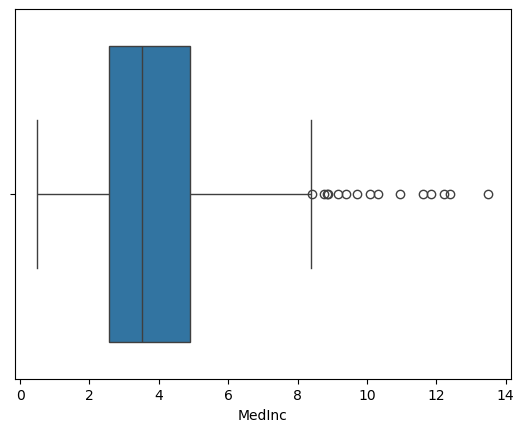

In [46]:
sns.boxplot(df, x="MedInc")

<Axes: xlabel='HouseAge'>

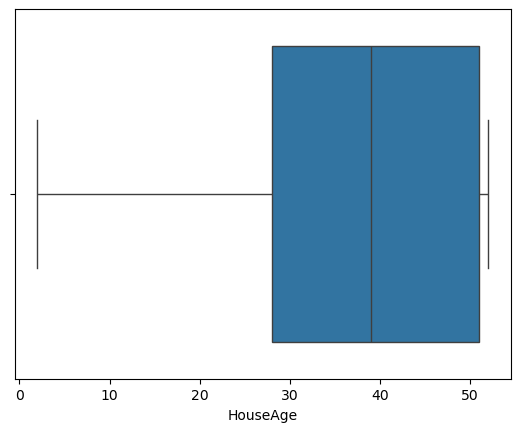

In [47]:
sns.boxplot(df, x="HouseAge")

<Axes: xlabel='AveOccup'>

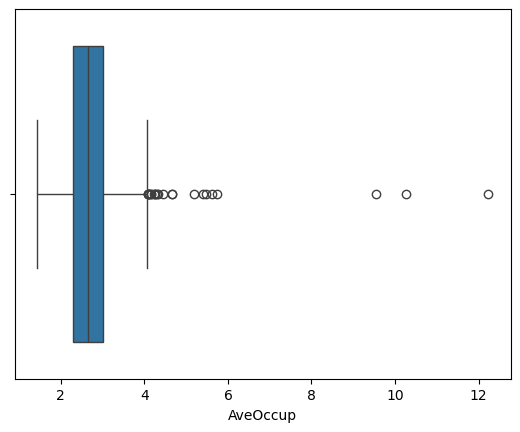

In [48]:
sns.boxplot(df, x="AveOccup")

In [49]:
Q1 = np.percentile(df.MedInc, 25)
Q3 = np.percentile(df.MedInc, 75)
IQR = Q3 - Q1 # межквартильное расстояние
df_plt = df[(df.MedInc > Q1 - 1.5*IQR) & (df.MedInc < Q3 + 1.5*IQR)]


<Axes: xlabel='MedInc'>

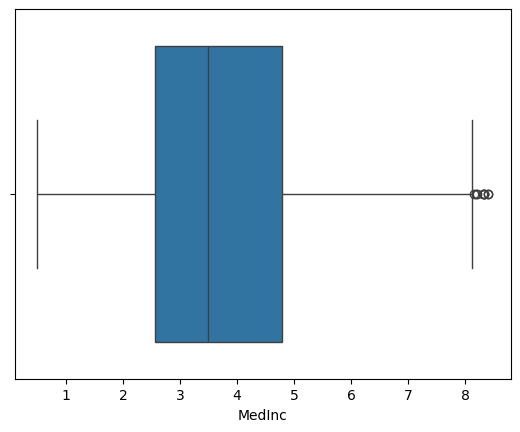

In [50]:
sns.boxplot(df_plt, x="MedInc")

In [51]:
df_plt

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
994,3.9864,12.0,5.255858,0.983130,2595.0,2.432052,37.71,-121.73,2.002
995,4.8624,11.0,5.680000,1.044706,5826.0,2.741647,37.71,-121.75,1.924
997,4.7361,22.0,6.080220,1.036264,2474.0,2.718681,37.70,-121.80,2.168
998,5.4324,17.0,5.975831,0.965257,2222.0,3.356495,37.69,-121.80,2.155


In [52]:
Q1 = np.percentile(df.AveOccup, 25)
Q3 = np.percentile(df.AveOccup, 75)
IQR = Q3 - Q1 # межквартильное расстояние
df_plt = df[(df.AveOccup > Q1 - 1.5*IQR) & (df.AveOccup < Q3 + 1.5*IQR)]

<Axes: xlabel='AveOccup'>

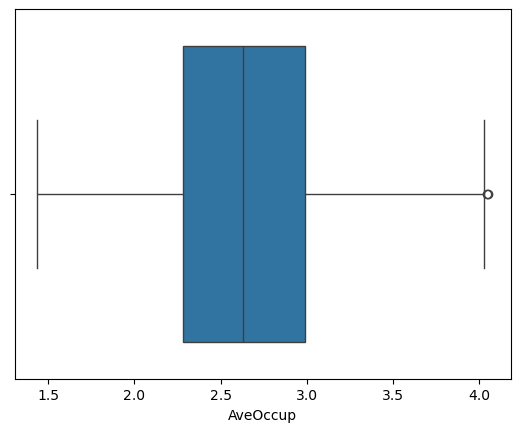

In [53]:
sns.boxplot(df_plt, x="AveOccup")

In [54]:
import statsmodels.formula.api as smf

lm = smf.ols("MedHouseVal~MedInc+AveOccup+HouseAge", df_plt).fit()
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            MedHouseVal   R-squared:                       0.721
Model:                            OLS   Adj. R-squared:                  0.720
Method:                 Least Squares   F-statistic:                     838.3
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          3.78e-269
Time:                        20:41:35   Log-Likelihood:                -640.81
No. Observations:                 977   AIC:                             1290.
Df Residuals:                     973   BIC:                             1309.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.7667      0.102     17.375      0.000       1.567       1.966
MedInc         0.4075      0.009     47.539      0.000       0.391       0.424
AveOccup      -0.5014      0.029    -17.107      0.000      -0.559      -0.444
HouseAge       0.0022      0.001      1.828      0.068      -0.000       0.004
==============================================================================
Omnibus:                      260.012   Durbin-Watson:                   1.490
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1472.585
Skew:                           1.094   Prob(JB):                         0.00
Kurtosis:                       8.602   Cond. No.                         279.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Вывод: Проанализировав матрицу парный корреляций между факторными признаками, а также корреляционные связи между результативным признаком и факторными, были выявлены некоторые пары факторов в которых возникает мультиколлинеарность. В дальнейшем, с помощью функции sns.pairplot, также были построены модели для наглядного анализа взаимосвязей. После, по полученным результатам, было построенно несколько моделей регрессии (результативный признак предопределен в задаче) с различными комбинациями наиболее подходящих факторных признаков. (Для множественной модели регрессии было выбрано взять 3 факторных признака). Оценив получившиеся модели была выбрана одна, с наимольшим коэффициентом детерминации(0,613) (Из "грязных" моделей она описывает изменение результативного признака наилучшим образом). Далее для увеличения точности модели утвержденные факторные признаки были проверенны на выбросы с помощью визуализации диаграммы boxplot. Выбросы были выялены в факторах : AveOccup, MedInc. Далее факторные признаки были очищены от выбросов методом Тьюки, после чего были включены в конечную модель. На выходе была получена модель регрессии без выбросов в значениях, с коэффициентом детерминации 0,721. (Что говорит о том, что модель стала "чище", результативный признак описывается факторными лучше, чем в модели, построенной до определения и удаления выбросов).